# Phase 1 — Data Quality & Sanity Checks

Walkthrough script. Run as `python notebooks/streamflix/01_data_quality.py` from the
project root, or convert to a Jupyter notebook cell by cell.

Before ANY statistical analysis, we answer 4 questions:
    1. Did randomization work?           -> SRM (chi-square on group sizes)
    2. Are users on the right page?      -> group vs landing_page cross-tab
    3. Are users in only one group?      -> duplicate user_id check
    4. Are baseline attributes balanced? -> covariate balance check

If ANY check fails, the experiment cannot be analyzed for ship/no-ship
without remediation. Verifying data integrity first is the foundation of
trustworthy experimentation.

In [1]:
import os
import sys
import warnings
from pathlib import Path

# The analysis code uses paths relative to the project root, so run from there.
PROJECT_ROOT = Path.cwd().parents[1] if Path.cwd().name == "streamflix" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", message="Glyph .* missing from font")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.data.loader import load_experiment
from src.analysis.sanity_checks import check_srm

## 1. Load the data

In [2]:
df = load_experiment("data/experiment.csv").dropna(subset=["group"])
FIG_DIR = Path("reports/figures/streamflix")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}\n")
print(df.head())

Shape: (100000, 14)
Columns: ['user_id', 'timestamp', 'group', 'landing_page', 'country', 'device', 'source', 'is_returning', 'prior_watch_hours', 'converted', 'trial_watch_hours', 'distinct_titles', 'day7_active', 'page_load_ms']

   user_id           timestamp      group  landing_page country   device  \
0  1029790 2026-04-01 00:00:20  treatment  personalized      US      Web   
1  1082885 2026-04-01 00:00:31    control     top_picks      UK      Web   
2  1037217 2026-04-01 00:01:44  treatment  personalized   Other  Android   
3  1048257 2026-04-01 00:01:45  treatment  personalized      CA      Web   
4  1053311 2026-04-01 00:01:50    control     top_picks      US      Web   

        source  is_returning  prior_watch_hours  converted  trial_watch_hours  \
0      organic         False               0.02          0               8.79   
1      organic         False               0.01          0               4.75   
2  paid_social         False               0.00          0          

## 2. SRM check — Did randomization work?

In [3]:
# We expect a 50/50 split. We use the very strict alpha = 0.001 because
# false positives are costly (we'd block a valid experiment).
srm = check_srm(df, group_col="group", expected_ratio={"control": 0.5, "treatment": 0.5})
print("\n=== SRM check ===")
print(srm)
if srm.p_value < 0.01:
    print("\n⚠️  Borderline: this passes the strict alpha = 0.001 alert threshold but "
          "would fail at 0.01.\n   Treat it as a data-quality incident to localize, "
          "not as a clean pass.")
print("\n💡 Interpretation: If SRM fails, suspect a bug. Look for:")
print("   - Asymmetric platform/device behavior (e.g., Android-only bug)")
print("   - Bot or crawler traffic in one arm")
print("   - Survivorship in tracking (one arm drops events)")


=== SRM check ===
✅ PASS
  Observed: {'control': 50461, 'treatment': 49539}
  Expected: {'control': 50000.0, 'treatment': 50000.0}
  Chi-square: 8.5008, p-value: 0.003550

⚠️  Borderline: this passes the strict alpha = 0.001 alert threshold but would fail at 0.01.
   Treat it as a data-quality incident to localize, not as a clean pass.

💡 Interpretation: If SRM fails, suspect a bug. Look for:
   - Asymmetric platform/device behavior (e.g., Android-only bug)
   - Bot or crawler traffic in one arm
   - Survivorship in tracking (one arm drops events)


## 3. Assignment integrity — Are users on the right page?

In [4]:
# Treatment users should ONLY see 'personalized'. Control -> 'top_picks'.
print("\n=== Group vs landing_page cross-tab ===")
crosstab = df.groupby(["group", "landing_page"]).size().unstack(fill_value=0)
print(crosstab)

mismatched = df[
    ((df["group"] == "control") & (df["landing_page"] != "top_picks")) |
    ((df["group"] == "treatment") & (df["landing_page"] != "personalized"))
]
mismatch_rate = len(mismatched) / len(df)
print(f"\nMismatched rows: {len(mismatched):,} ({mismatch_rate:.3%})")
print("💡 Interpretation: <0.5% is usually tolerable (caching, race conditions).")
print("   Higher than that = systemic issue. Decision: drop these rows OR")
print("   analyze as ITT (intent-to-treat, using assignment not actual exposure).")


=== Group vs landing_page cross-tab ===
landing_page  personalized  top_picks
group                                
control                 48      50413
treatment            49474         65

Mismatched rows: 113 (0.113%)
💡 Interpretation: <0.5% is usually tolerable (caching, race conditions).
   Higher than that = systemic issue. Decision: drop these rows OR
   analyze as ITT (intent-to-treat, using assignment not actual exposure).


## 4. Duplicate users — Are any users in BOTH groups?

In [5]:
users_per_group = df.groupby("user_id")["group"].nunique()
multi_group = users_per_group[users_per_group > 1]
print(f"\n=== Duplicate users ===")
print(f"Users appearing in multiple groups: {len(multi_group):,}")
print("💡 In real experiments this happens via: deleted cookies, multi-device,")
print("   shared accounts. Common cleaning rules: drop them, or keep first.")


=== Duplicate users ===
Users appearing in multiple groups: 0
💡 In real experiments this happens via: deleted cookies, multi-device,
   shared accounts. Common cleaning rules: drop them, or keep first.


## 5. Covariate balance — finer-grained randomization check


=== Covariate balance (categorical) ===

--- country --- ✅
         control_%  treatment_%  gap_pp   flag
country                                       
AU            8.05         8.09    0.03  False
CA           10.02        10.24    0.22  False
Other        22.02        21.91   -0.11  False
UK           15.18        14.86   -0.32  False
US           44.73        44.91    0.18  False

--- device --- 🚨 IMBALANCE
         control_%  treatment_%  gap_pp   flag
device                                        
Android      35.56        34.47   -1.09   True
TV           10.09        10.04   -0.05  False
Web          24.46        25.00    0.54  False
iOS          29.89        30.48    0.60  False

--- source --- ✅
             control_%  treatment_%  gap_pp   flag
source                                            
organic          39.92        39.89   -0.03  False
paid_search      24.93        24.96    0.03  False
paid_social      20.24        20.22   -0.01  False
referral         14.91      


Saved -> reports/figures/streamflix/01_categorical_balance.png

=== Covariate balance (continuous: prior_watch_hours) ===
Control   mean: 2.0907  std: 4.4024  n: 50,461
Treatment mean: 2.1129  std: 4.4234  n: 49,539
Welch t-test:   t = -0.796, p = 0.4258


Saved -> reports/figures/streamflix/01_continuous_balance.png


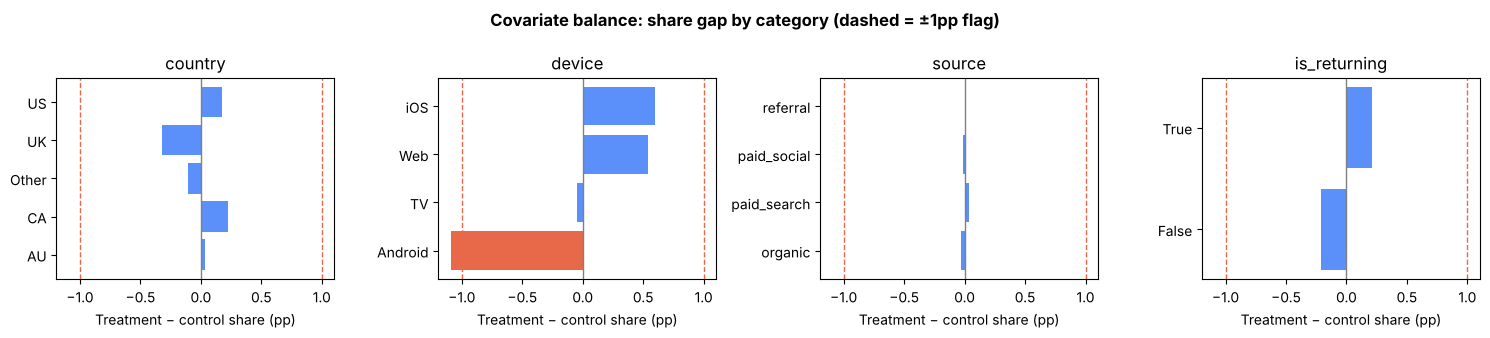

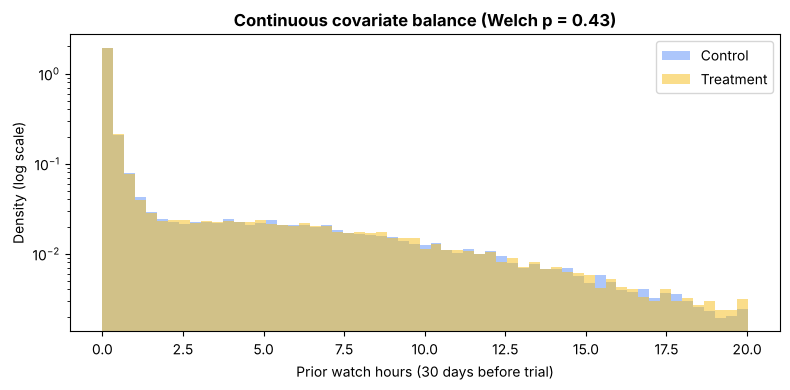

In [6]:
# Even when overall SRM passes, individual attribute distributions
# should be balanced across arms. Imbalances reveal subtle assignment
# leaks that an overall chi-square can miss (e.g. a device-specific bug).
# Industry rule of thumb: flag any category with |gap| > 1pp.
from scipy import stats

FLAG_THRESHOLD_PP = 1.0
CATEGORICAL = ["country", "device", "source", "is_returning"]

print("\n=== Covariate balance (categorical) ===")
flagged_cols = []
gaps = {}
for col in CATEGORICAL:
    share = (
        df.groupby(["group", col]).size()
        / df.groupby("group").size()
    ).unstack(level="group") * 100
    share.columns = [f"{c}_%" for c in share.columns]
    share["gap_pp"] = (share["treatment_%"] - share["control_%"]).round(3)
    share["flag"] = share["gap_pp"].abs() > FLAG_THRESHOLD_PP
    flag_marker = " 🚨 IMBALANCE" if share["flag"].any() else " ✅"
    print(f"\n--- {col} ---{flag_marker}")
    print(share.round(2).to_string())
    if share["flag"].any():
        flagged_cols.append(col)
    gaps[col] = share["gap_pp"]

fig, axes = plt.subplots(1, len(CATEGORICAL), figsize=(15, 3.4), sharex=True)
for ax, col in zip(axes, CATEGORICAL):
    g = gaps[col]
    colors = ["#E8684A" if abs(v) > FLAG_THRESHOLD_PP else "#5B8FF9" for v in g.values]
    ax.barh([str(i) for i in g.index], g.values, color=colors)
    ax.axvline(0, color="gray", linewidth=1)
    for x in (-FLAG_THRESHOLD_PP, FLAG_THRESHOLD_PP):
        ax.axvline(x, color="#E8684A", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Treatment − control share (pp)")
fig.suptitle("Covariate balance: share gap by category (dashed = ±1pp flag)", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_categorical_balance.png", dpi=140, bbox_inches="tight")
print(f"\nSaved -> {FIG_DIR}/01_categorical_balance.png")

# Continuous covariate — Welch's t-test
print("\n=== Covariate balance (continuous: prior_watch_hours) ===")
c = df.loc[df["group"] == "control", "prior_watch_hours"]
t = df.loc[df["group"] == "treatment", "prior_watch_hours"]
t_stat, p_val = stats.ttest_ind(c, t, equal_var=False)
print(f"Control   mean: {c.mean():.4f}  std: {c.std():.4f}  n: {len(c):,}")
print(f"Treatment mean: {t.mean():.4f}  std: {t.std():.4f}  n: {len(t):,}")
print(f"Welch t-test:   t = {t_stat:+.3f}, p = {p_val:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, np.percentile(df["prior_watch_hours"], 99), 60)
ax.hist(c, bins=bins, density=True, alpha=0.5, color="#5B8FF9", label="Control")
ax.hist(t, bins=bins, density=True, alpha=0.5, color="#F6BD16", label="Treatment")
ax.set_yscale("log")
ax.set_xlabel("Prior watch hours (30 days before trial)")
ax.set_ylabel("Density (log scale)")
ax.set_title(f"Continuous covariate balance (Welch p = {p_val:.2f})", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_continuous_balance.png", dpi=140, bbox_inches="tight")
print(f"Saved -> {FIG_DIR}/01_continuous_balance.png")

## 6. Verdict

In [7]:
print("\n" + "=" * 70)
print("DATA QUALITY VERDICT")
print("=" * 70)
if flagged_cols:
    print(f"⚠️  Imbalance detected in: {flagged_cols}")
    print("   Combined with the borderline SRM result, this is consistent "
          "with a\n   segment-specific assignment leak. Downstream analysis "
          "should report\n   ITT as primary and include a sensitivity "
          "analysis excluding the affected\n   segment to demonstrate "
          "robustness of the headline conclusion.")
else:
    print("✅ Randomization checks pass. Proceeding to inference.")


DATA QUALITY VERDICT
⚠️  Imbalance detected in: ['device']
   Combined with the borderline SRM result, this is consistent with a
   segment-specific assignment leak. Downstream analysis should report
   ITT as primary and include a sensitivity analysis excluding the affected
   segment to demonstrate robustness of the headline conclusion.
